# Crop Recommendation Classification using Soil and Weather Features
**Course:** 23CSE301 Machine Learning — Capstone Project (Review 1)  
**Dataset:** `Crop_recommendation.csv` (2,200 records, 22 classes)  
**Problem Statement:** Classify the crop label from soil and environmental measurements using the five Part-A classification algorithms required for Review 1.  
**Target Variable:** `label` (22 agricultural crop categories)

## 2. Imports and Configuration

**What:** Import required libraries and set global configurations.  
**Why:** Ensure standard data processing, stratified splits, and consistent plot formatting.  
**How:** Import Pandas, NumPy, Matplotlib, Seaborn, and Scikit-Learn modules with `random_state=42`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Configuration
random_state = 42
np.random.seed(random_state)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 3. Load Dataset

**What:** Load and inspect the classification dataset.  
**Why:** Verify dataset dimensions, column names, and sample values before analysis.  
**How:** Load `Crop_recommendation.csv` using Pandas and display basic dimensions and the first few rows.

In [2]:
# Load dataset using relative path
data_path = '../data/Crop_recommendation.csv' if os.path.exists('../data/Crop_recommendation.csv') else 'data/Crop_recommendation.csv'
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 2200 rows, 8 columns


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


## 4. Dataset Audit

**What:** Audit dataset integrity, missing values, duplicates, and class distribution.  
**Why:** Confirm that features are correctly typed and verify class balance.  
**How:** Check null counts, duplicates, numerical summaries, and dynamic class counts.

In [4]:
audit_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
audit_summary

In [5]:
print(f"Duplicate rows count: {df.duplicated().sum()}")
class_counts = df['label'].value_counts()
print(f"Total crop classes: {len(class_counts)}")
print(f"Samples per class: min={class_counts.min()}, max={class_counts.max()}")
print(f"All classes perfectly equal: {(class_counts == 100).all()}")

Duplicate rows count: 0
Total crop classes: 22
Samples per class: min=100, max=100
All classes perfectly equal: True


In [6]:
# Numerical summary
df.describe().T[['min', 'mean', '50%', 'max', 'std']].round(2)

**Observation:**
1. The classification dataset contains exactly 2,200 rows and 8 columns with zero missing values and zero duplicate rows.
2. The target variable `label` has 22 unique crop categories, with exactly 100 records per crop, confirming a perfectly balanced multi-class dataset.
3. The 7 numerical predictors (N, P, K, temperature, humidity, pH, rainfall) represent soil chemistry and micro-climate indicators with diverse numerical ranges.

## 5. Exploratory Data Analysis (EDA)

**What:** Explore class distribution, feature spreads, correlation structure, and bivariate relationships as clear, individual plots.  
**Why:** Assess feature distributions, multicollinearity, and crop separation with full-sized readability.  
**How:** Plot individual class counts, feature histograms, correlation heatmap, and scatter plots.

### 5.1 Class Distribution

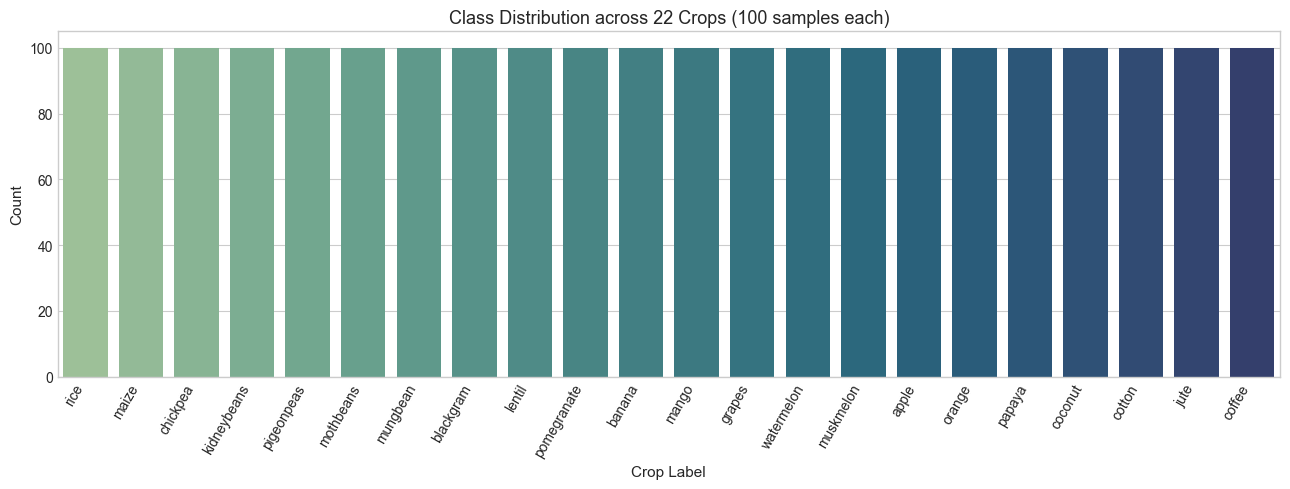

In [7]:
plt.figure(figsize=(13, 5))
sns.countplot(data=df, x='label', order=df['label'].value_counts().index, palette='crest')
plt.title('Class Distribution across 22 Crops (100 samples each)', fontsize=13)
plt.xlabel('Crop Label', fontsize=11)
plt.ylabel('Count', fontsize=11)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

**Observation:** The dataset is uniformly balanced with exactly 100 observations per crop class, preventing majority class bias during training.

### 5.2 Numerical Feature Distributions

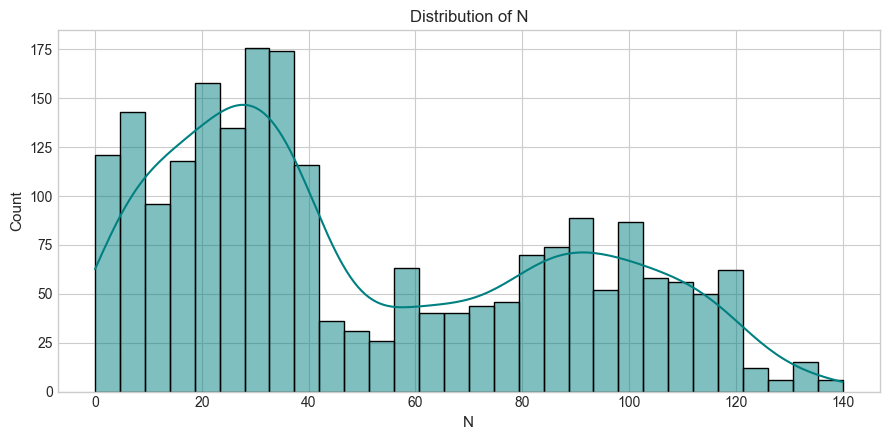

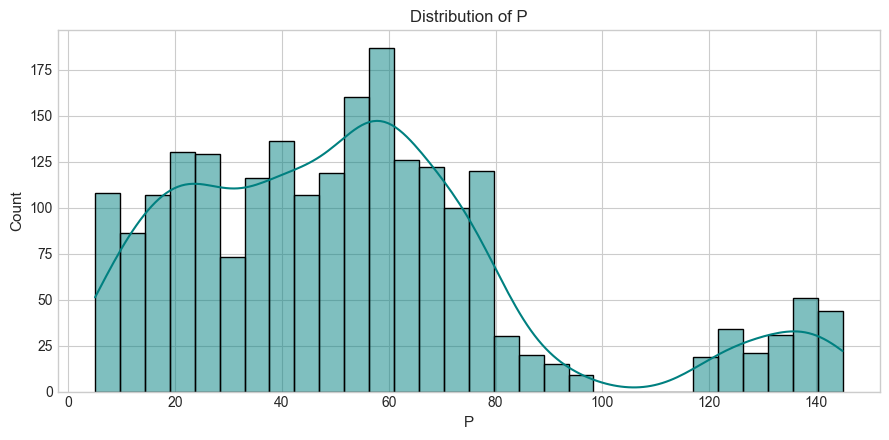

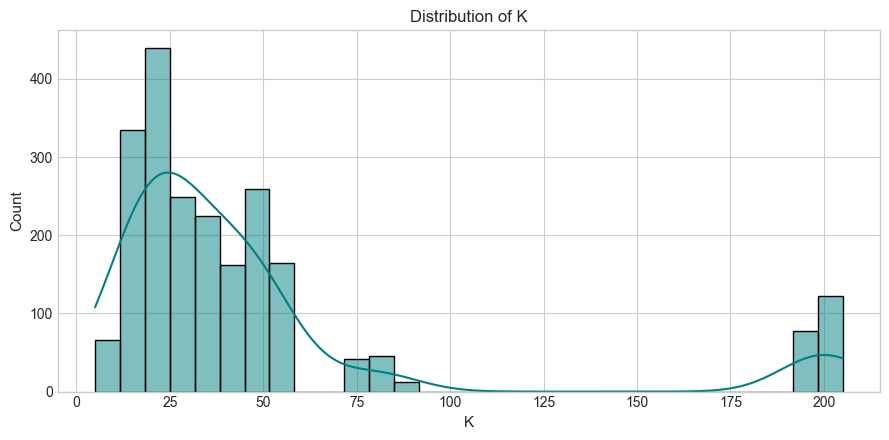

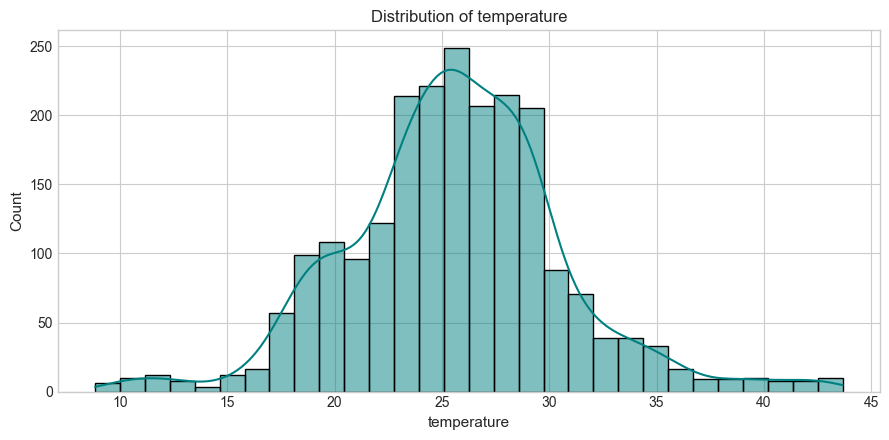

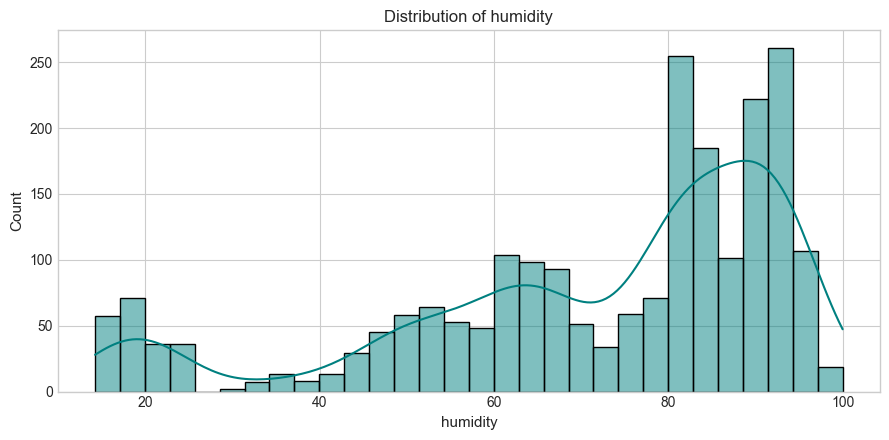

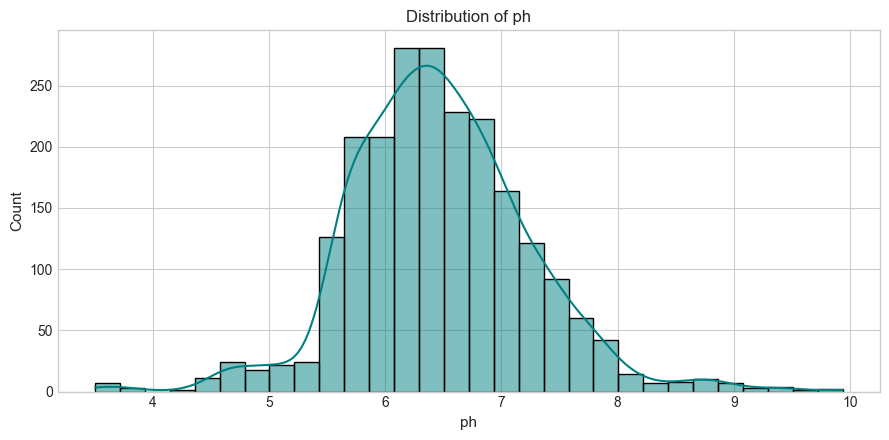

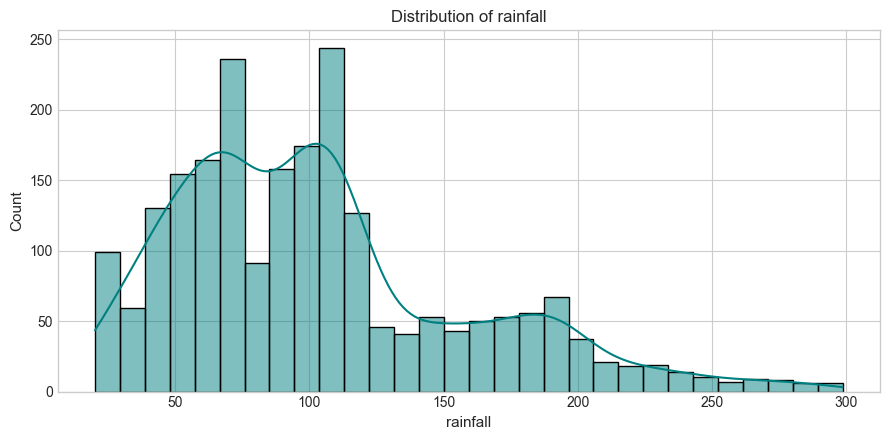

In [8]:
# Individual distribution plots for each soil and weather predictor
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for col in features:
    plt.figure(figsize=(9, 4.5))
    sns.histplot(df[col], bins=30, kde=True, color='teal')
    plt.title(f'Distribution of {col}', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Count', fontsize=11)
    plt.tight_layout()
    plt.show()

**Observation:**
1. Soil nutrients (N, P, K) exhibit multi-modal distributions, reflecting specific nutrient affinity groups (e.g. legumes fixing low N, heavy potassium feeders having high K).
2. Soil pH is approximately normally distributed around neutral (mean 6.47, range 3.5 to 9.9).
3. Rainfall shows distinct clusters corresponding to arid, sub-tropical, and wetland cultivation regimes.

### 5.3 Correlation Heatmap

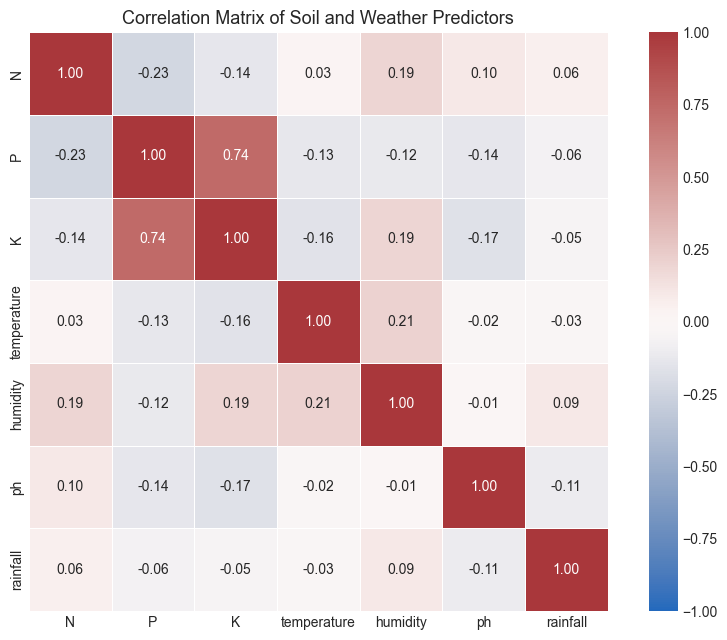

In [9]:
plt.figure(figsize=(8.5, 6.5))
corr = df[features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Soil and Weather Predictors', fontsize=13)
plt.tight_layout()
plt.show()

**Observation:**
1. Phosphorus (P) and Potassium (K) show a moderate positive correlation ($r = 0.74$), which aligns with basal fertilizer management.
2. Other predictors have low pairwise correlation ($|r| < 0.25$), confirming that the 7 features capture largely complementary environmental dimensions.

### 5.4 Feature Relationship Scatter Plots

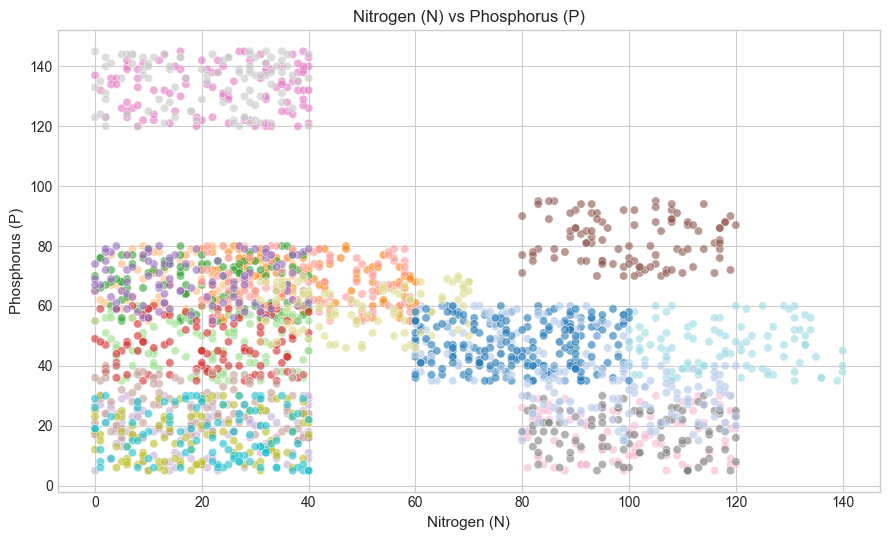

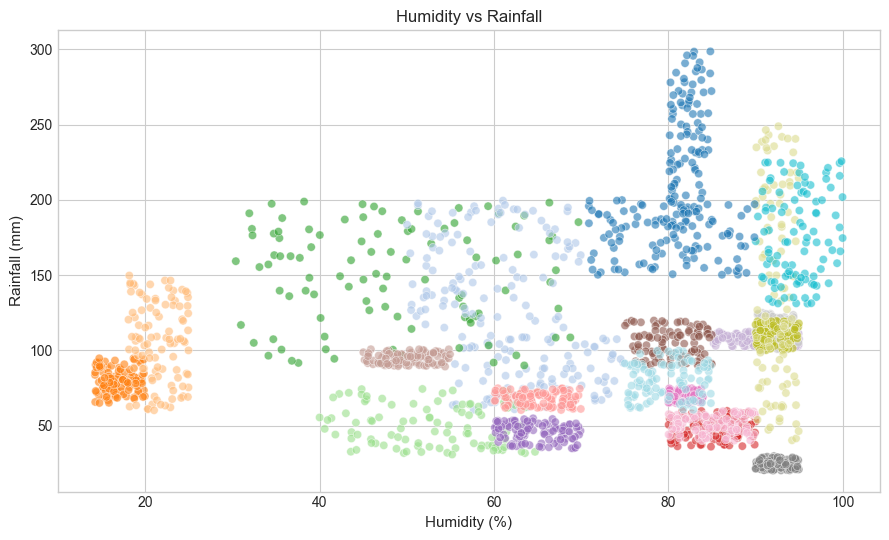

In [10]:
# 1. Nitrogen (N) vs Phosphorus (P)
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x='N', y='P', hue='label', legend=False, alpha=0.6, palette='tab20')
plt.title('Nitrogen (N) vs Phosphorus (P)', fontsize=12)
plt.xlabel('Nitrogen (N)', fontsize=11)
plt.ylabel('Phosphorus (P)', fontsize=11)
plt.tight_layout()
plt.show()

# 2. Humidity vs Rainfall
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x='humidity', y='rainfall', hue='label', legend=False, alpha=0.6, palette='tab20')
plt.title('Humidity vs Rainfall', fontsize=12)
plt.xlabel('Humidity (%)', fontsize=11)
plt.ylabel('Rainfall (mm)', fontsize=11)
plt.tight_layout()
plt.show()

**Observation:** The scatter plots reveal distinct clustering in sub-spaces: crops occupy well-defined ecological niches (e.g. rice in high humidity and rainfall; chickpea and kidneybeans in high P and moderate N). This spatial separation indicates that non-linear classifiers should perform effectively.

## 6. Data Quality

**What:** Evaluate data quality, range validity, and apparent outliers.  
**Why:** Ensure extreme values reflect genuine agronomic requirements rather than erroneous data entry.  
**How:** Inspect boxplots across all features and evaluate agronomic validity before making any removal decision.

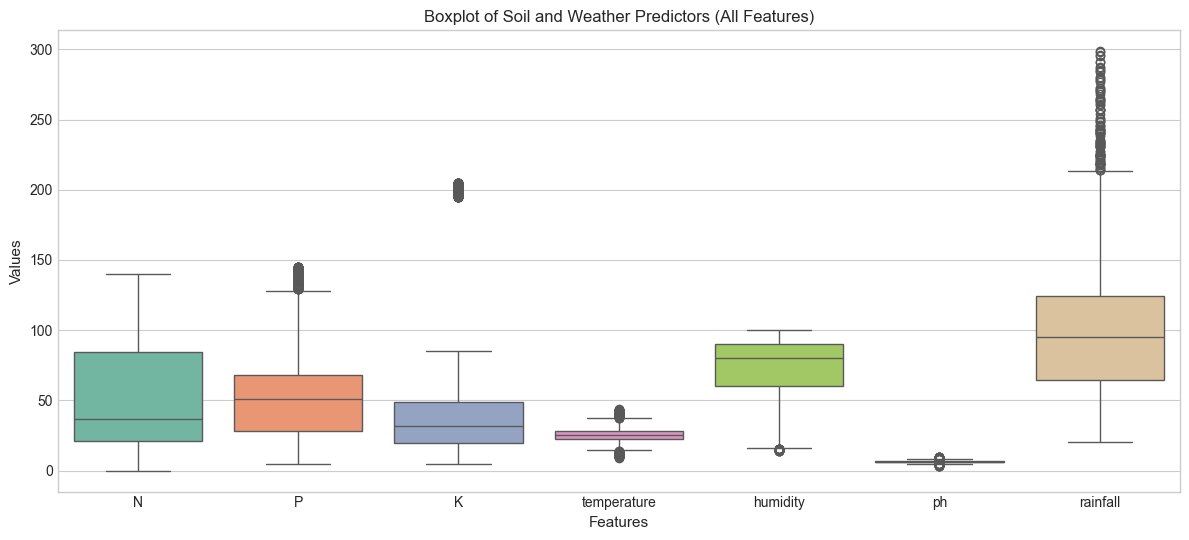

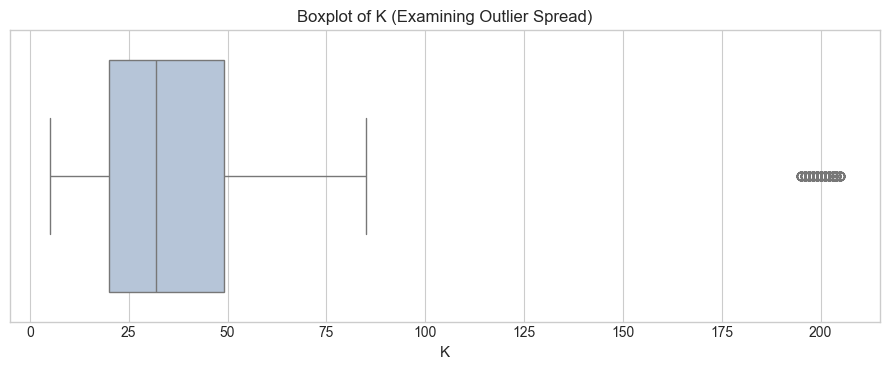

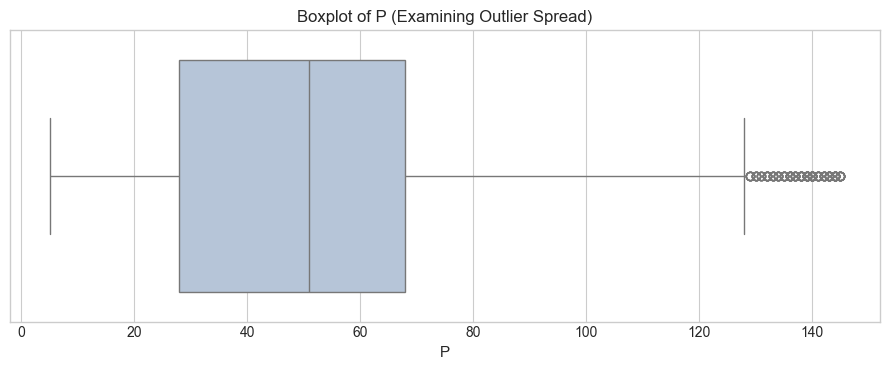

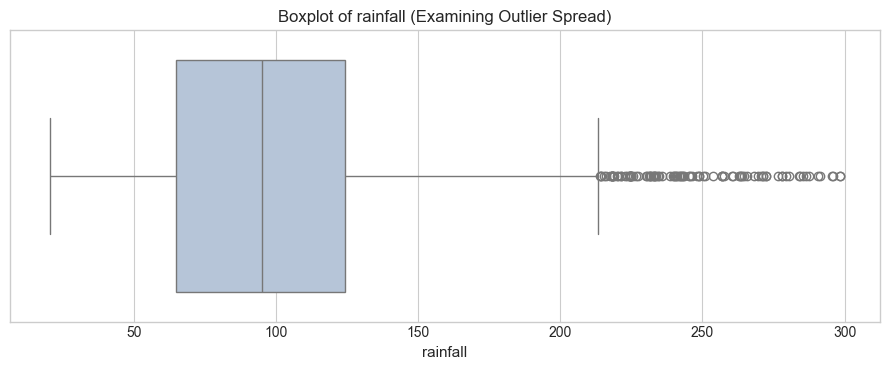

In [11]:
# Overall boxplot for all features
plt.figure(figsize=(12, 5.5))
sns.boxplot(data=df[features], palette='Set2')
plt.title('Boxplot of Soil and Weather Predictors (All Features)', fontsize=12)
plt.xlabel('Features', fontsize=11)
plt.ylabel('Values', fontsize=11)
plt.tight_layout()
plt.show()

# Individual boxplots for high-variance nutrient predictors
for col in ['K', 'P', 'rainfall']:
    plt.figure(figsize=(9, 3.8))
    sns.boxplot(x=df[col], color='lightsteelblue')
    plt.title(f'Boxplot of {col} (Examining Outlier Spread)', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.tight_layout()
    plt.show()

**Observation and Treatment Decision:**
1. High values in Potassium ($K > 150$) and Phosphorus ($P > 120$) appear as statistical outliers under standard IQR rules.
2. In agricultural botany, specific fruit crops (such as grapes and apples) require exceptionally high potassium and phosphorus levels for sugar translocations.
3. **Decision:** These are valid botanical measurements, not measurement errors or corrupted records. We retain all 2,200 rows intact to preserve the distinguishing profiles of these crops.

## 7. Train/Test Split

**What:** Partition the dataset into an 80% training set and a 20% held-out test set.  
**Why:** Maintain an unbiased evaluation set with identical class proportions across both partitions.  
**How:** Use `train_test_split` with `test_size=0.20`, `stratify=y`, and `random_state=42`.

In [12]:
X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=random_state, stratify=y
)

print(f"Training set shape: {X_train.shape} (exactly {len(y_train) // 22} per class)")
print(f"Testing set shape:  {X_test.shape} (exactly {len(y_test) // 22} per class)")

Training set shape: (1760, 7) (exactly 80 per class)
Testing set shape:  (440, 7) (exactly 20 per class)


## 8. Preprocessing

**What:** Standardise numerical features using `StandardScaler`.  
**Why:** Algorithms such as KNN, Logistic Regression, and SVC rely on distance or gradient norms and are sensitive to feature scales (e.g. Rainfall up to 300 mm vs pH around 6.5).  
**How:** Embed `StandardScaler` inside Scikit-Learn `Pipeline` objects for each classifier, ensuring scaling is fitted *strictly on training data*.